# BDI KDE Candidate Exploration

This notebook provides a reusable function for visualizing BDI bootstrap distance distributions
against any candidate author. Run the setup cells first, then explore candidates in bulk.

In [21]:
import sys

sys.path.insert(0, "/Users/ben/code/bdi")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import re
import logging

from sklearn.preprocessing import StandardScaler, LabelEncoder
from bdi import BDIVerifier

logging.basicConfig(level="INFO")

import mpl_fontkit as fk

fk.install("Roboto Condensed")

Font name: `Roboto Condensed`


## Data Setup

In [23]:
raw_df = pd.read_csv("output.csv", encoding="utf-8")

label_encoder = LabelEncoder()
raw_df.insert(1, "author_label", label_encoder.fit_transform(raw_df["Author"]))

numeric_cols = raw_df.select_dtypes(include=["number"]).columns
numeric_cols = numeric_cols[numeric_cols != "author_label"]

scaler = StandardScaler(with_mean=False).fit(raw_df[numeric_cols])
df_scaled = pd.DataFrame(scaler.transform(raw_df[numeric_cols]), columns=numeric_cols)
df_scaled["author_label"] = raw_df["author_label"].values

print(f"Loaded {df_scaled.shape[0]} rows, {len(numeric_cols)} features")
print(f"Authors: {raw_df['Author'].unique()}")

Loaded 657 rows, 21 features
Authors: <ArrowStringArray>
[ 'AI', 'AeC', 'AeP',  'BC',   'B',  'DC',   'E',  'FB', 'GAp', 'GAr',  'GC',
  'GM',  'GP', 'GVS', 'GiP',  'HA',  'HP',   'H',  'IH',  'II',   'M', 'NLC',
  'OM', 'OSE',  'RC',  'RT',  'SG', 'U10', 'U11',  'U1',  'U2',  'U3',  'U4',
  'U5',  'U6',  'U7',  'U8',  'U9',  'X2',   'X']
Length: 40, dtype: str


In [24]:
# Split: Ecclesiastes as problem, everyone else as comparison
x_label = label_encoder.transform(["X2"])[0]
print("X label:", x_label)

problem_mask = raw_df["author_label"] == x_label

problem_X = df_scaled.loc[problem_mask].drop(columns=["author_label"]).copy()
comparison_X = df_scaled.loc[~problem_mask].drop(columns=["author_label"]).copy()
comparison_y = df_scaled.loc[~problem_mask, "author_label"].values

problem_indices = raw_df.loc[problem_mask].index

print(
    f"Problem chunks: {problem_X.shape[0]} | Comparison docs: {comparison_X.shape[0]}"
)


X label: 39
Problem chunks: 1 | Comparison docs: 656


In [25]:
# Fit the BDI verifier (minmax, no feature selection)
rng = np.random.default_rng(42)

verifier = BDIVerifier(
    metric="minmax",
    nb_bootstrap_iter=1000,
    rnd_prop=0.35,
    random_state=rng,
)
verifier.fit(comparison_X, comparison_y)
print("Verifier fitted.")

09/03/2026 11:34:40 [bdi:INFO] Fitting on 656 documents...


Verifier fitted.


## KDE Plotting Function

In [27]:
def plot_kde_viridis(dist_df, poem_names, title="", xlabel="", ax=None):
    """Plot KDE curves colored by chunk number using viridis plasma.

    Later chunks (higher number in poem name) get darker colors.
    """
    chunk_nums = []
    for idx in dist_df.columns:
        name = poem_names.loc[idx, "Poem"] if idx in poem_names.index else str(idx)
        m = re.search(r"(\d+)", name)
        chunk_nums.append(int(m.group(1)) if m else 0)

    chunk_nums = np.array(chunk_nums)

    if chunk_nums.max() > chunk_nums.min():
        norm_vals = (chunk_nums - chunk_nums.min()) / (
            chunk_nums.max() - chunk_nums.min()
        )
    else:
        norm_vals = np.ones(len(chunk_nums)) * 0.5

    cmap = cm.plasma
    colors = [cmap(v) for v in norm_vals]

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 3))

    for col, color in zip(dist_df.columns, colors):
        sns.kdeplot(dist_df[col], color=color, linewidth=1, alpha=0.7, ax=ax)

    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set(xlabel=xlabel, ylabel="Density", title=title)

    sm = cm.ScalarMappable(
        cmap=cmap,
        norm=mcolors.Normalize(vmin=chunk_nums.min(), vmax=chunk_nums.max()),
    )
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Chunk number")

    return ax


def plot_kde_vs_candidate(
    verifier: BDIVerifier,
    problem_X: pd.DataFrame,
    candidate: str,
    label_encoder: LabelEncoder,
    problem_indices: pd.Index,
    raw_df: pd.DataFrame,
    problem_mask: pd.Series,
    title_suffix: str = "",
    ax: plt.Axes | None = None,
) -> pd.DataFrame:
    """Run BDI against a candidate and plot the bootstrap distance KDE.

    Args:
        verifier: A fitted BDIVerifier instance.
        problem_X: Feature matrix for the problem chunks (without author_label).
        candidate: Author label string to test against (e.g. 'H', 'M').
        label_encoder: Fitted LabelEncoder for author names.
        problem_indices: Original DataFrame indices for the problem rows.
        raw_df: The original (unscaled) DataFrame with a 'Poem' column.
        problem_mask: Boolean mask for the problem rows in raw_df.
        title_suffix: Optional extra text for the plot title.
        ax: Optional matplotlib Axes to plot on. If None, creates new figure.

    Returns:
        DataFrame of bootstrap distances (chunks × bootstrap iterations).
    """
    label_idx = label_encoder.transform([candidate])[0]
    probas = verifier.predict_proba(problem_X, [label_idx] * problem_X.shape[0])

    dist_df = pd.DataFrame(dict(zip(problem_indices, verifier._dist_arrays)))

    mean_str = np.mean(probas)
    poem_names = raw_df.loc[problem_mask]
    title = (
        f"In primum caput Ecclesiastes vs {candidate}{title_suffix}  (match strength: {mean_str:.3f})"
    )
    xlabel = "Bootstrap Distance (1000 iters, minmax, 90% feature space)"

    if ax is None:
        _, ax = plt.subplots(figsize=(8, 3))

    plot_kde_viridis(dist_df, poem_names, title=title, xlabel=xlabel, ax=ax)

    return dist_df

## Explore Candidates

Edit the `candidates` list and re-run to explore different authors.

09/03/2026 11:34:40 [bdi:INFO] Predicting on 1 documents


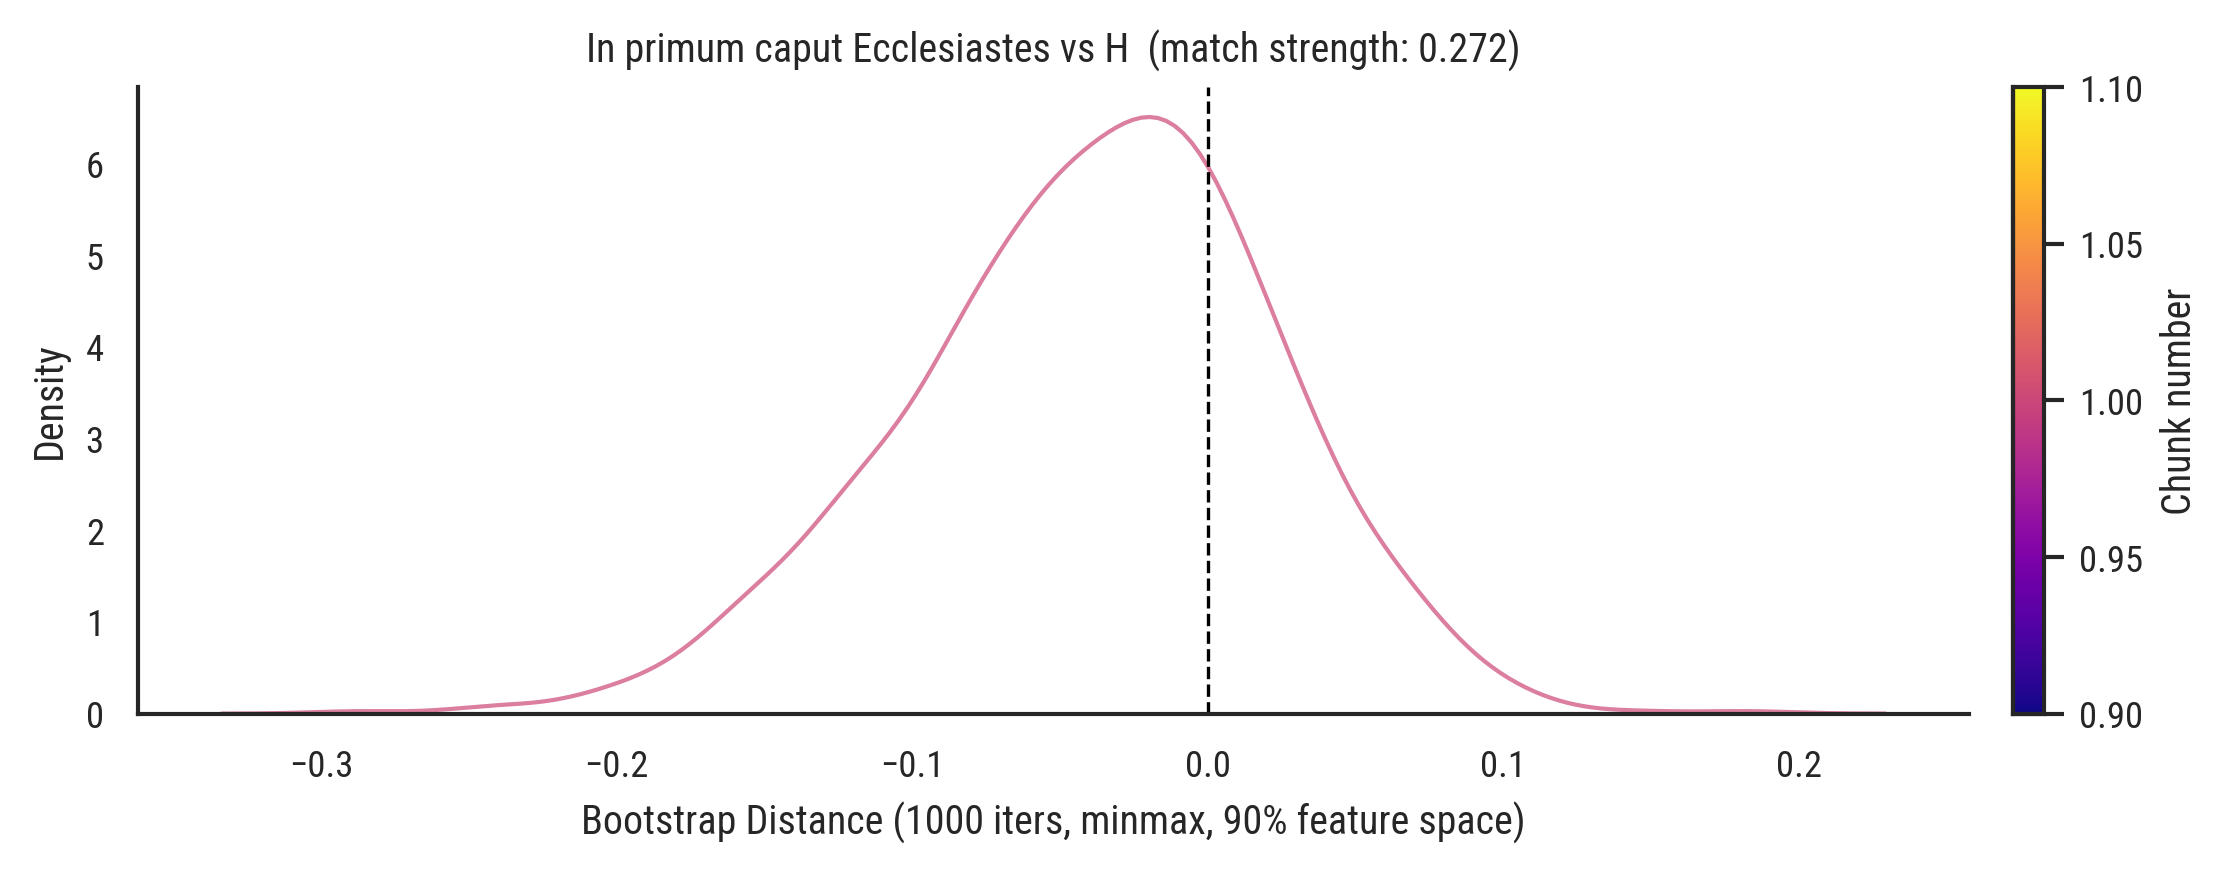

09/03/2026 11:34:41 [bdi:INFO] Predicting on 1 documents
09/03/2026 11:34:41 [bdi:INFO] Predicting on 1 documents


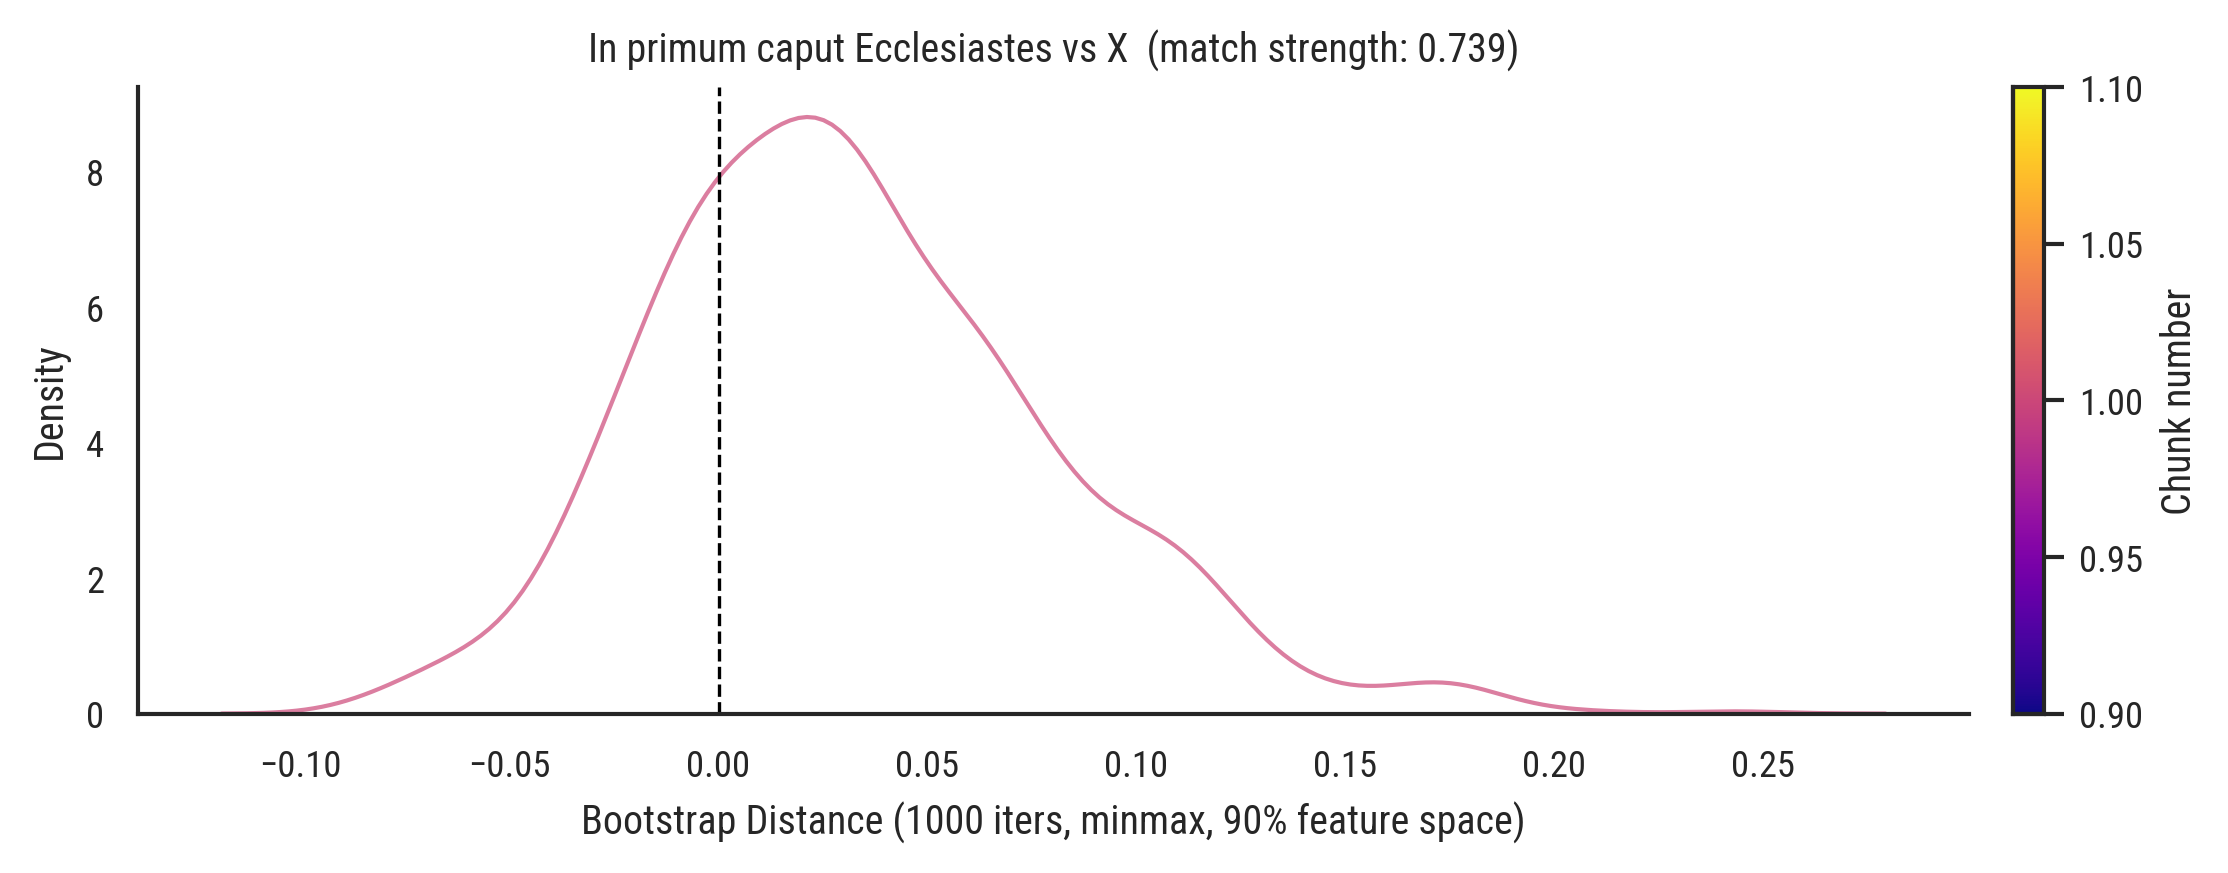

09/03/2026 11:34:41 [bdi:INFO] Predicting on 1 documents
09/03/2026 11:34:41 [bdi:INFO] Predicting on 1 documents


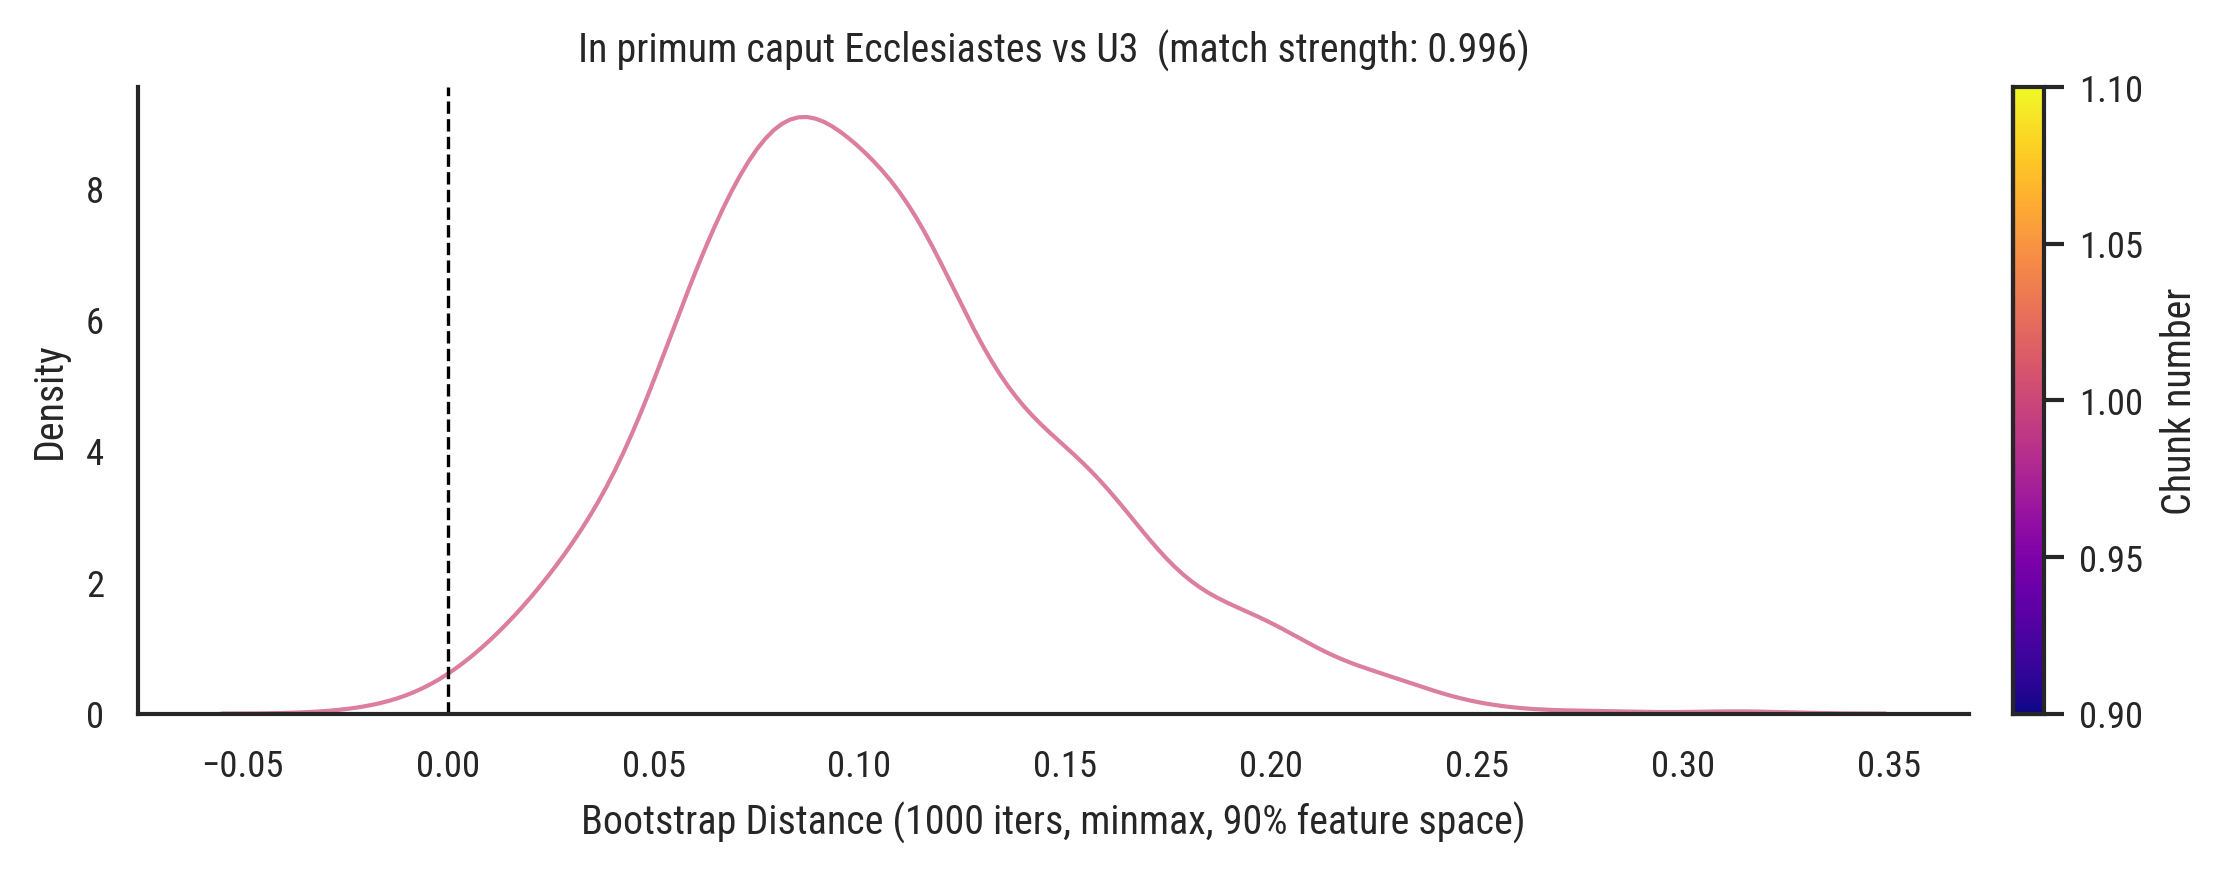

09/03/2026 11:34:41 [bdi:INFO] Predicting on 1 documents


In [29]:
# === EDIT THIS LIST ===
candidates = ["H", "X", "U3"]
# ======================

sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={"figure.figsize": (8, 3), "figure.dpi": 300},
)

all_results = {}
for candidate in candidates:
    if candidate not in label_encoder.classes_:
        print(f"Skipping '{candidate}': not in label encoder")
        continue
    fig, ax = plt.subplots(figsize=(8, 3))
    dist_df = plot_kde_vs_candidate(
        verifier,
        problem_X,
        candidate,
        label_encoder,
        problem_indices,
        raw_df,
        problem_mask,
        ax=ax,
    )
    sns.despine()
    fig.tight_layout()
    plt.savefig("forest_plot_minmax.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Store summary
    label_idx = label_encoder.transform([candidate])[0]
    probas = verifier.predict_proba(problem_X, [label_idx] * problem_X.shape[0])
    all_results[candidate] = {"mean": np.mean(probas), "std": np.std(probas)}

## Summary Table

In [31]:
summary = pd.DataFrame(all_results).T
summary = summary.sort_values("mean", ascending=False)
summary.columns = ["Match Strength (mean)", "Match Strength (std)"]
print(summary.to_string())

    Match Strength (mean)  Match Strength (std)
U3                  0.992                   0.0
X                   0.752                   0.0
H                   0.299                   0.0
